# 09 · Explore and clean reported crime (NYPD complaints)
**Know Before You Rent · Team BUTA**

**Datasets**
- [NYPD Complaint Data Historic](https://data.cityofnewyork.us/d/qgea-i56i): through last year.
- [NYPD Complaint Data Current (Year To Date)](https://data.cityofnewyork.us/d/5uac-w243): this year.

Both are downloaded from January 2025 through October 2026. **One row = one crime reported to the NYPD**, with offense, severity (felony, misdemeanor or violation), date and location.

**Role in the project:** neighborhood context for a renter ("how much crime is reported around this building?") and a candidate model feature (the `crime_` group in notebook 11).

**Responsible use**
- We **do not download** the suspect and victim demographic columns.
- Reported crime also reflects where police patrol and who calls 911, so it is not a pure measure of danger.
- For privacy, NYPD places reports at the middle of the street segment, not the exact address. That's why we count crime within **200 m**, not 100 m.

**Study window: January 1, 2025–October 31, 2026.** Annual comparisons should use January–October in both years. Housing prediction uses six-month histories and four-month outcomes; older figures and reports describe the previous study.

In [1]:
import sys, pathlib, json
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config, housing as H, clean_housing as C, features_housing as F
from src.preprocess import CleaningReport
from src.plots import save, ACCENT, MUTED

pd.set_option("display.float_format", "{:,.2f}".format)
raw = pd.concat([H.load("crime_historic"), H.load("crime_current")], ignore_index=True)
print(f"{len(raw):,} reported crimes (historic: {H.monthly_rows('crime_historic').sum():,}, "
      f"current year: {H.monthly_rows('crime_current').sum():,})")
H.overview(raw)

1,006,599 reported crimes (historic: 579,561, current year: 427,038)


,missing_%,distinct,example
cmplnt_num,0.00,1006599,299742614
cmplnt_fr_dt,0.00,2934,2025-01-20T00:00:00.000
rpt_dt,0.00,638,2025-01-20T00:00:00.000
ky_cd,0.00,69,578
ofns_desc,0.00,58,HARRASSMENT 2
law_cat_cd,0.00,3,VIOLATION
crm_atpt_cptd_cd,0.00,2,COMPLETED
boro_nm,0.00,6,STATEN ISLAND
addr_pct_cd,0.00,78,123
loc_of_occur_desc,0.00,6,FRONT OF


## 1. Volume, severity and offense types

In [2]:
raw["rpt_dt"] = pd.to_datetime(raw["rpt_dt"].astype(str), errors="coerce")
last_year = raw["rpt_dt"].dt.year.max()
common_last_month = min(10, raw.loc[raw["rpt_dt"].dt.year == last_year, "rpt_dt"].dt.month.max())
comparable = raw[raw["rpt_dt"].dt.month <= common_last_month]
print(f"Year comparisons use January–month {common_last_month}; missing source months are unavailable, not zero.")
display(pd.crosstab(comparable["rpt_dt"].dt.year, comparable["law_cat_cd"]))
raw["ofns_desc"].value_counts().head(20).to_frame("reports")

Year comparisons use January–month 9; missing source months are unavailable, not zero.


law_cat_cd,FELONY,MISDEMEANOR,VIOLATION
rpt_dt,,,
2025,142989,227123,68928
2026,136006,222182,68850


,reports
ofns_desc,
PETIT LARCENY,181260
HARRASSMENT 2,151606
ASSAULT 3 & RELATED OFFENSES,107135
GRAND LARCENY,82052
CRIMINAL MISCHIEF & RELATED OF,61572
FELONY ASSAULT,52637
VEHICLE AND TRAFFIC LAWS,46433
MISCELLANEOUS PENAL LAW,34905
DANGEROUS DRUGS,33124


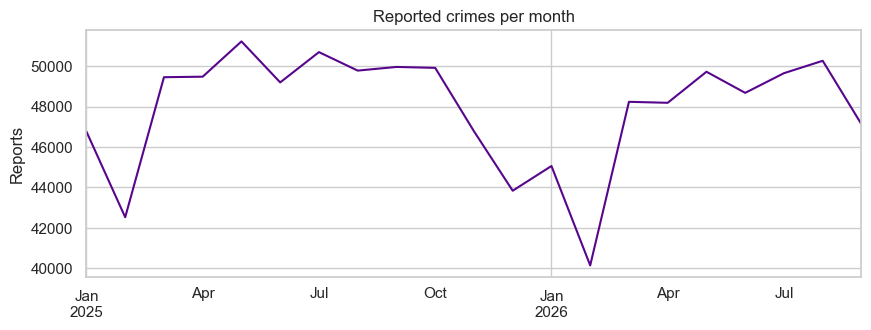

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.2))
raw.groupby(raw["rpt_dt"].dt.to_period("M")).size().plot(ax=ax, color=ACCENT)
ax.set(title="Reported crimes per month", xlabel="", ylabel="Reports")
save(fig, "rent12a_crime_per_month")

## 2. Data quality: locations

In [4]:
lat = pd.to_numeric(raw["latitude"], errors="coerce")
print(f"Missing coordinates: {lat.isna().mean():.1%} | zero coordinates: {(lat == 0).mean():.1%}")
print(f"Duplicate report ids: {raw['cmplnt_num'].duplicated().sum():,}")
raw["prem_typ_desc"].value_counts().head(10).to_frame("reports by premises")

Missing coordinates: 0.0% | zero coordinates: 0.0%


Duplicate report ids: 0


,reports by premises
prem_typ_desc,
STREET,304101
RESIDENCE - APT. HOUSE,223852
RESIDENCE-HOUSE,89931
RESIDENCE - PUBLIC HOUSING,63381
TRANSIT - NYC SUBWAY,58263
CHAIN STORE,49425
OTHER,18834
DEPARTMENT STORE,18733
COMMERCIAL BUILDING,17633


## 3. Clean

In [5]:
rep = CleaningReport("crime")
crime = C.clean_crime(raw, rep)
display(pd.DataFrame(rep.steps)[["step", "rows_before", "rows_after", "rows_removed", "detail"]])
display(pd.Series(C.CRIME_GROUPS, name="regex pattern").to_frame())
pd.crosstab(crime["crime_group"], crime["severity"], margins=True).sort_values("All", ascending=False)

,step,rows_before,rows_after,rows_removed,detail
0,load_raw,1006599,1006599,0,historic + current year
1,drop_duplicate_cmplnt_num,1006599,1006599,0,
2,parse_dates,1006599,1006599,0,missing or pre-2025 rpt_dt
3,valid_coordinates,1006599,1006594,5,"missing, zero or outside-NYC coordinates"
4,derive_fields,1006594,1006594,0,"severity, crime group (regex), in-residence flag"


,regex pattern
violent,MURDER|HOMICIDE|RAPE|SEX CRIME|ROBBERY|FELONY ...
property,BURGLARY|LARCENY|THEFT|STOLEN|CRIMINAL MISCHIE...
drugs/weapons,DANGEROUS DRUGS|DANGEROUS WEAPONS|CANNABIS|MAR...
harassment,HARR?ASS?MENT|MENACING|OFF\. AGNST PUB ORD


severity,FELONY,MISDEMEANOR,VIOLATION,All
crime_group,,,,
All,324146,522011,160437,1006594
property,172934,254900,0,427834
violent,83913,123220,0,207133
harassment,0,30739,151606,182345
other,41703,89395,8701,139799
drugs/weapons,25596,23757,130,49483


In [6]:
# Spot-check the regex groups
crime.astype({"ofns_desc": object}).groupby("crime_group")["ofns_desc"].agg(lambda s: s.value_counts().head(4).index.tolist()).to_frame("top offenses")

,top offenses
crime_group,
drugs/weapons,"[DANGEROUS DRUGS, DANGEROUS WEAPONS, CANNABIS ..."
harassment,"[HARRASSMENT 2, OFF. AGNST PUB ORD SENSBLTY &]"
other,"[VEHICLE AND TRAFFIC LAWS, MISCELLANEOUS PENAL..."
property,"[PETIT LARCENY, GRAND LARCENY, CRIMINAL MISCHI..."
violent,"[ASSAULT 3 & RELATED OFFENSES, FELONY ASSAULT,..."


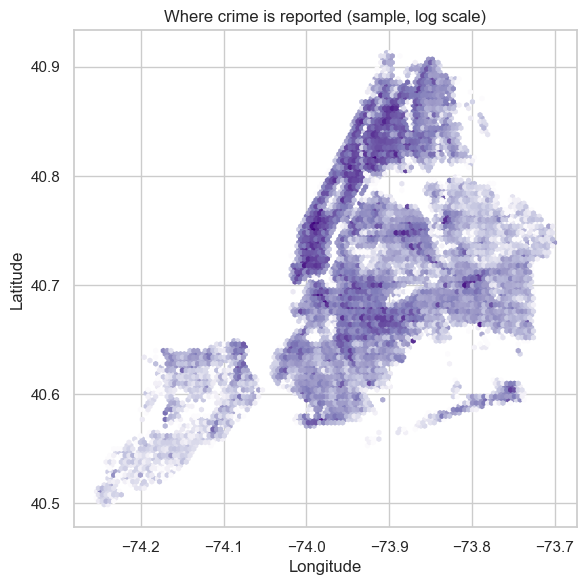

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 7))
sample = crime.sample(min(300_000, len(crime)), random_state=0)
hb = ax.hexbin(sample["longitude"], sample["latitude"], gridsize=120, bins="log", cmap="Purples", mincnt=1)
ax.set_aspect(1 / np.cos(np.radians(40.7)))
ax.set(title="Where crime is reported (sample, log scale)", xlabel="Longitude", ylabel="Latitude")
save(fig, "rent12b_crime_map")

## 4. Crime around residential buildings (within 200 m)

In [8]:
inp = F.load_inputs() | {"crime": crime}
universe = F.building_universe(inp["pluto"], inp["landlords"])
around = F.crime_counts(universe, crime, [2025, 2026], exposure_years=sum(m.days_in_month for m in crime["rpt_dt"].dt.to_period("M").unique()) / 365.25)
around.describe(percentiles=[.25, .5, .75, .9]).T

,count,mean,std,min,25%,50%,75%,90%,max
crime_total,"172,468.00",194.09,177.17,0.00,75.57,136.83,254.19,415.06,"2,449.69"
crime_felony,"172,468.00",63.91,54.72,0.00,26.33,48.09,84.73,132.82,"1,064.26"
crime_in_residence,"172,468.00",74.63,65.06,0.00,30.34,54.39,95.61,161.44,753.40
crime_violent,"172,468.00",41.47,46.57,0.00,12.59,26.33,53.24,92.74,583.37
crime_property,"172,468.00",82.20,91.31,0.00,33.20,54.39,97.32,164.31,"1,916.70"
crime_drugs_weapons,"172,468.00",9.98,22.07,0.00,1.14,2.86,9.16,24.04,540.43
crime_harassment,"172,468.00",34.66,28.54,0.00,14.31,25.76,45.80,75.00,237.58


In [9]:
# Is crime nearby related to housing problems? (rank correlation with complaints per apartment, 2025–October 2026)
comp = pd.read_parquet(C.OUT["hpd_complaints"], columns=["bbl", "complaint_id", "received_date", "year"])
comp = comp[comp["received_date"] < crime["rpt_dt"].max().normalize() + pd.Timedelta(days=1)]
per_bldg = comp[comp["year"].isin([2025, 2026])].groupby("bbl")["complaint_id"].nunique()
rate = pd.Series(per_bldg.reindex(universe["bbl"]).fillna(0).to_numpy() / universe["unitsres"].to_numpy(), index=universe.index)
around.rank().corrwith(rate.rank()).rename("Spearman ρ with complaints per apartment").to_frame()

,Spearman ρ with complaints per apartment
crime_total,0.30
crime_felony,0.30
crime_in_residence,0.31
crime_violent,0.29
crime_property,0.27
crime_drugs_weapons,0.25
crime_harassment,0.32


## 5. Save

In [10]:
crime.to_parquet(C.OUT["crime"], index=False)
(config.REPORTS_DIR / "cleaning_report_crime.json").write_text(json.dumps(rep.to_dict(), indent=2, default=str))
print(f"Saved {len(crime):,} rows → {C.OUT['crime'].relative_to(ROOT)}")

Saved 1,006,594 rows → data\processed\crime_clean.parquet


## Findings

Run the cells above to inspect results for the shared January 2025–October 2026 study. Previous-window metrics are not reused.